<a href="https://colab.research.google.com/github/sonujose123/ML-Project-Sentiment-Analysis/blob/main/Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as snd
import nltk
from nltk.stem.porter import PorterStemmer
nltk.download('stopwords')
from nltk.corpus import stopwords
STOPWORDS = set(stopwords.words('english'))
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from wordcloud import wordcloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
import pickle
import re




[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Exploratory Data Analysis

In [5]:
data = pd.read_csv('amazon_alexa.tsv', delimiter = '\t', quoting=3)
print(f"Dataset: {data.shape}")



Dataset: (3150, 5)


In [6]:
data.head()

,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"""Sometimes while playing a game, you can answe...",1
3,5,31-Jul-18,Charcoal Fabric,"""I have had a lot of fun with this thing. My 4...",1
4,5,31-Jul-18,Charcoal Fabric,Music,1


In [7]:
print(f"Feature names: {data.columns.values}")

Feature names: ['rating' 'date' 'variation' 'verified_reviews' 'feedback']


In [8]:
# Check for null values
print(data.isnull().sum())

rating              0
date                0
variation           0
verified_reviews    1
feedback            0
dtype: int64


In [9]:
# Getting the record where verified_reviews is null
data[data['verified_reviews'].isnull() == True]

,rating,date,variation,verified_reviews,feedback
473,2,29-Jun-18,White,NaN,0


In [10]:
# Drop the null record
data.dropna(inplace=True)

In [11]:
# Create a new 'length' column that will contain the length of the strings in the verified_reviews column
data['length'] = data['verified_reviews'].apply(len)
data.head()

,rating,date,variation,verified_reviews,feedback,length
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1,13
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1,9
2,4,31-Jul-18,Walnut Finish,"""Sometimes while playing a game, you can answe...",1,197
3,5,31-Jul-18,Charcoal Fabric,"""I have had a lot of fun with this thing. My 4...",1,174
4,5,31-Jul-18,Charcoal Fabric,Music,1,5


In [12]:
# Datatypes of the features
data.dtypes

,0
rating,int64
date,object
variation,object
verified_reviews,object
feedback,int64
length,int64


In [13]:
# Analyzing 'rating' column

len(data)
print(f"Rating value count: \n {data['rating'].value_counts()}")

Rating value count: 
 rating
5    2286
4     455
1     161
3     152
2      95
Name: count, dtype: int64


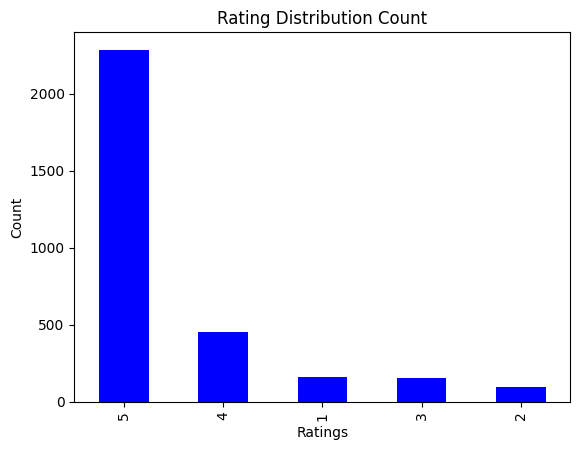

In [14]:
# Visualize the total count for each rating
data['rating'].value_counts().plot.bar(color = 'blue')
plt.title("Rating Distribution Count")
plt.xlabel('Ratings')
plt.ylabel('Count')
plt.show()

In [15]:
# Analyzing 'feedback' column

print(f"Feedback count: \n {data['feedback'].value_counts()}")


Feedback count: 
 feedback
1    2893
0     256
Name: count, dtype: int64


In [16]:
# feedback = 0

review_0 = data[data['feedback'] == 0].iloc[0]['verified_reviews']
print(review_0)  # Output indicates feedback = 0 means negative feedback

"It's like Siri, in fact, Siri answers more accurately then Alexa.  I don't see a real need for it in my household, though it was a good bargain on prime day deals."


In [17]:
# feedback = 1

review_1 = data[data['feedback'] == 1].iloc[11]['verified_reviews']
print(review_1) # Output indicates feedback = 1 means positive feedback

I love it! Learning knew things with it eveyday! Still figuring out how everything works but so far it's been easy to use and understand. She does make me laugh at times


In [18]:
# Analyzing 'rating' column

print(f"Rating count: \n {data['rating'].value_counts()}")

Rating count: 
 rating
5    2286
4     455
1     161
3     152
2      95
Name: count, dtype: int64


In [19]:
# feedback = 0. Negative feedback rating

data[data['feedback' ]== 0]['rating'].value_counts()


,count
rating,
1,161
2,95


In [20]:
# feedback = 1. Positive feedback rating

data[data['feedback' ]== 1]['rating'].value_counts()


,count
rating,
5,2286
4,455
3,152


In [21]:
# Analyzing 'variation' column

print(f" Variation value count: \n {data['variation'].value_counts()}")

 Variation value count: 
 variation
Black  Dot                      516
Charcoal Fabric                 430
Configuration: Fire TV Stick    350
Black  Plus                     270
Black  Show                     265
Black                           261
Black  Spot                     241
White  Dot                      184
Heather Gray Fabric             157
White  Spot                     109
Sandstone Fabric                 90
White                            90
White  Show                      85
White  Plus                      78
Oak Finish                       14
Walnut Finish                     9
Name: count, dtype: int64


In [22]:
#Mean rating according to variations

data.groupby('variation')['rating'].mean()

,rating
variation,
Black,4.233716
Black Dot,4.453488
Black Plus,4.370370
Black Show,4.490566
Black Spot,4.311203
Charcoal Fabric,4.730233
Configuration: Fire TV Stick,4.591429
Heather Gray Fabric,4.694268
Oak Finish,4.857143


In [23]:
cv = CountVectorizer(stop_words='english')
words = cv.fit_transform(data.verified_reviews)

In [24]:
!pip install wordcloud

In [25]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

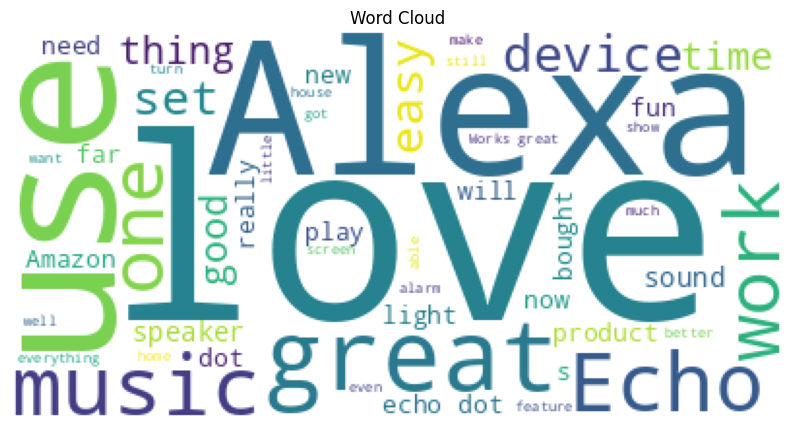

In [26]:
# Combine all reviews
reviews = " ".join([review for review in data['verified_reviews']])

# Initialize world cloud object
wc = WordCloud(background_color='white', max_words=50)

# Plot Wordcloud
plt.figure(figsize=(10,10))
plt.imshow(wc.generate(reviews))
plt.title("Word Cloud")
plt.axis('off')
plt.show()







In [27]:
negative_reviews = " ".join([review for review in data[data['feedback'] == 0]['verified_reviews']])


negative_reviews = negative_reviews.lower().split()



positve_reviews = " ".join([review for review in data[data['feedback'] == 1]['verified_reviews']])
positve_reviews = positve_reviews.lower().split()

unique_negative = [x for x in negative_reviews if x not in positve_reviews]
unique_negative = " ".join(unique_negative)


unique_positive = [x for x in positve_reviews if x not in negative_reviews]
unique_positive = " ".join(unique_positive)




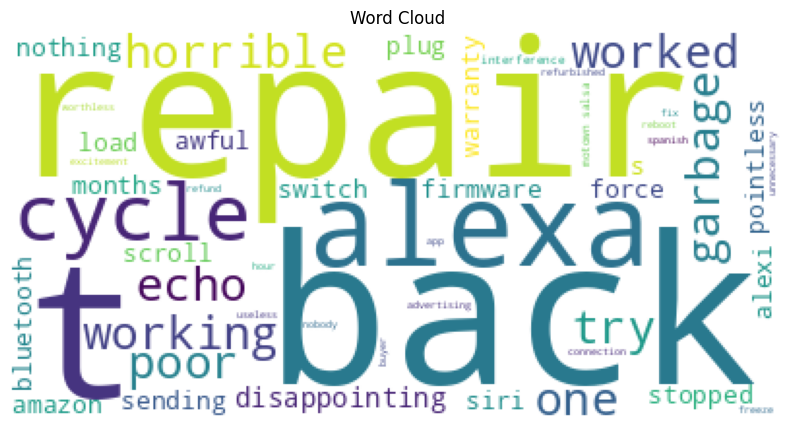

In [28]:
# Negative reviews word cloud


# Initialize world cloud object
wc = WordCloud(background_color='white', max_words=50)

# Plot Wordcloud
plt.figure(figsize=(10,10))
plt.imshow(wc.generate(unique_negative))
plt.title("Word Cloud")
plt.axis('off')
plt.show()



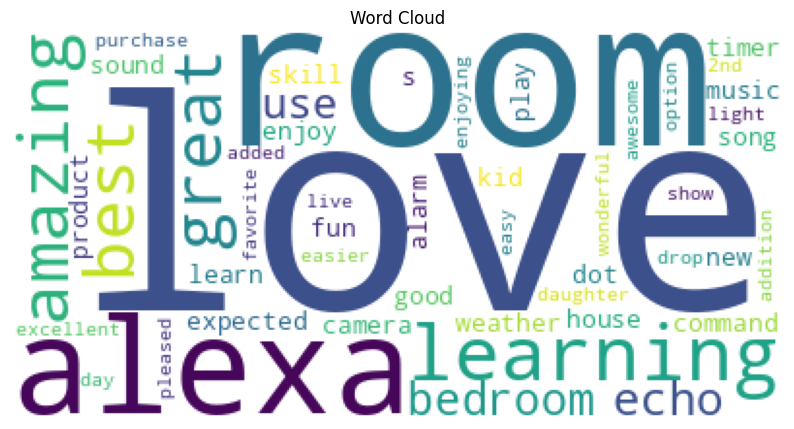

In [29]:
# Poisitve reviews word cloud


# Initialize world cloud object
wc = WordCloud(background_color='white', max_words=50)

# Plot Wordcloud
plt.figure(figsize=(10,10))
plt.imshow(wc.generate(unique_positive))
plt.title("Word Cloud")
plt.axis('off')
plt.show()

In [30]:
corpus = []
stemmer = PorterStemmer()
for i in range(0, data.shape[0]):
  review = re.sub('[^a-zA-Z]', ' ', data.iloc[i]['verified_reviews'])
  review = review.lower().split()
  review = [stemmer.stem(word) for word in review if not word in STOPWORDS]
  review = ' '.join(review)
  corpus.append(review)

In [31]:
cv = CountVectorizer(max_features = 2500)
X = cv.fit_transform(corpus).toarray()
y = data['feedback'].values



In [33]:
#pickle.dump(cv, open('Models/countVectorizer.pkl', 'wb'))

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=15)
print(f"X train: {X_train.shape}")
print(f"X test: {X_test.shape}")
print(f"y train: {y_train.shape}")
print(f"y test: {y_test.shape}")


X train: (2204, 2500)
X test: (945, 2500)
y train: (2204,)
y test: (945,)


In [36]:
scaler = MinMaxScaler()
X_train_scl = scaler.fit_transform(X_train)
X_test_scl =  scaler.transform(X_test)



In [ ]:
# Saving the scaler model
#pickle.dump(scaler, open('Models/scaler.pkl', 'wb'))


In [37]:
model_rf = RandomForestClassifier()
model_rf.fit(X_train_scl, y_train)

RandomForestClassifier()

In [38]:
print(f'Training Accuracy: ', model_rf.score(X_train_scl, y_train))
print(f'Test Accuracy: ', model_rf.score(X_test_scl, y_test))

Training Accuracy:  0.9941016333938294
Test Accuracy:  0.944973544973545


In [39]:
# Prediciting on the test test
y_pred = model_rf.predict(X_test_scl)

In [42]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[ 33  45]
 [  7 860]]
